# Clasificación de sentimientos en reseñas de películas utilizando LSTM

## Objetivo

Desarrollar un modelo de Deep Learning basado en una red neuronal recurrente LSTM
para clasificar reseñas de películas como positivas o negativas.

## Dataset

Se utilizará el conjunto de datos IMDB Movie Reviews, que contiene reseñas de
películas etiquetadas con dos categorías:

- 0: sentimiento negativo
- 1: sentimiento positivo

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import random

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
NUM_WORDS = 10000

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=NUM_WORDS
)

print("Reseñas de entrenamiento:", len(x_train))
print("Reseñas de prueba:", len(x_test))
print("Primera etiqueta:", y_train[0])
print("Primera reseña codificada:", x_train[0][:20])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Reseñas de entrenamiento: 25000
Reseñas de prueba: 25000
Primera etiqueta: 1
Primera reseña codificada: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]


In [3]:
print("Reseñas positivas en entrenamiento:", np.sum(y_train == 1))
print("Reseñas negativas en entrenamiento:", np.sum(y_train == 0))
print("Reseñas positivas en prueba:", np.sum(y_test == 1))
print("Reseñas negativas en prueba:", np.sum(y_test == 0))

Reseñas positivas en entrenamiento: 12500
Reseñas negativas en entrenamiento: 12500
Reseñas positivas en prueba: 12500
Reseñas negativas en prueba: 12500


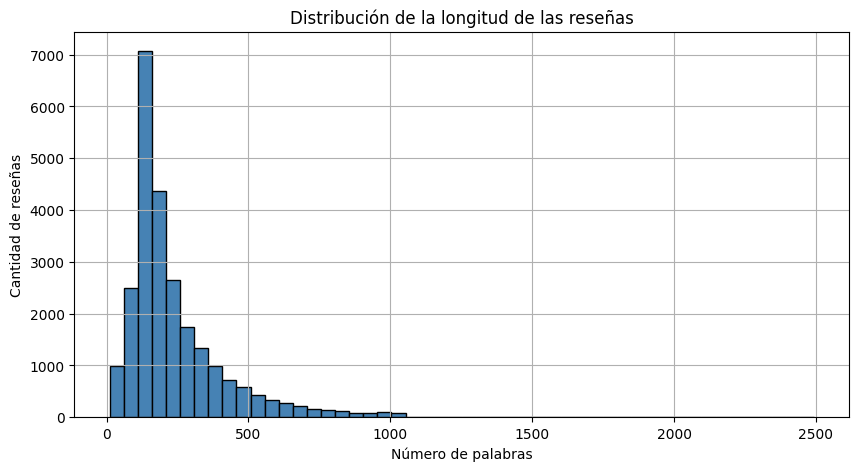

Longitud mínima: 11
Longitud máxima: 2494
Longitud promedio: 238.71364


In [4]:
longitudes = [len(reseña) for reseña in x_train]

plt.figure(figsize=(10, 5))
plt.hist(longitudes, bins=50, color="steelblue", edgecolor="black")
plt.title("Distribución de la longitud de las reseñas")
plt.xlabel("Número de palabras")
plt.ylabel("Cantidad de reseñas")
plt.grid()
plt.show()

print("Longitud mínima:", min(longitudes))
print("Longitud máxima:", max(longitudes))
print("Longitud promedio:", np.mean(longitudes))

In [5]:
MAX_LEN = 250

x_train_pad = pad_sequences(
    x_train,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

x_test_pad = pad_sequences(
    x_test,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Forma de x_train_pad:", x_train_pad.shape)
print("Forma de x_test_pad:", x_test_pad.shape)

Forma de x_train_pad: (25000, 250)
Forma de x_test_pad: (25000, 250)


In [6]:
from sklearn.model_selection import train_test_split

x_train_final, x_val, y_train_final, y_val = train_test_split(
    x_train_pad,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Entrenamiento:", x_train_final.shape)
print("Validación:", x_val.shape)
print("Prueba:", x_test_pad.shape)

Entrenamiento: (20000, 250)
Validación: (5000, 250)
Prueba: (25000, 250)


In [7]:
VOCAB_SIZE = 10000
EMBEDDING_DIM = 128

model = models.Sequential([
    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        input_length=MAX_LEN
    ),

    layers.Bidirectional(
        layers.LSTM(64, return_sequences=False)
    ),

    layers.Dropout(0.5),

    layers.Dense(32, activation="relu"),

    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "modelo_sentimientos_lstm.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    x_train_final,
    y_train_final,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=callbacks
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.6988 - loss: 0.5700 - precision: 0.7037 - recall: 0.6866 - val_accuracy: 0.8168 - val_loss: 0.4206 - val_precision: 0.8429 - val_recall: 0.7788
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.8623 - loss: 0.3571 - precision: 0.8577 - recall: 0.8687 - val_accuracy: 0.8596 - val_loss: 0.3526 - val_precision: 0.8298 - val_recall: 0.9048
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.9042 - loss: 0.2565 - precision: 0.9022 - recall: 0.9067 - val_accuracy: 0.8576 - val_loss: 0.3821 - val_precision: 0.8907 - val_recall: 0.8152
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.9359 - loss: 0.1844 - precision: 0.9372 - recall: 0.9343 - val_accuracy: 0.8618 - val_loss: 0.3853 - val_precision: 0.8585 - val_recall: 0.8664
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.9391 - loss: 0.1681 - precision: 0.9372 - recall: 0.9414 - val_accuracy: 0.8534 - val_lo

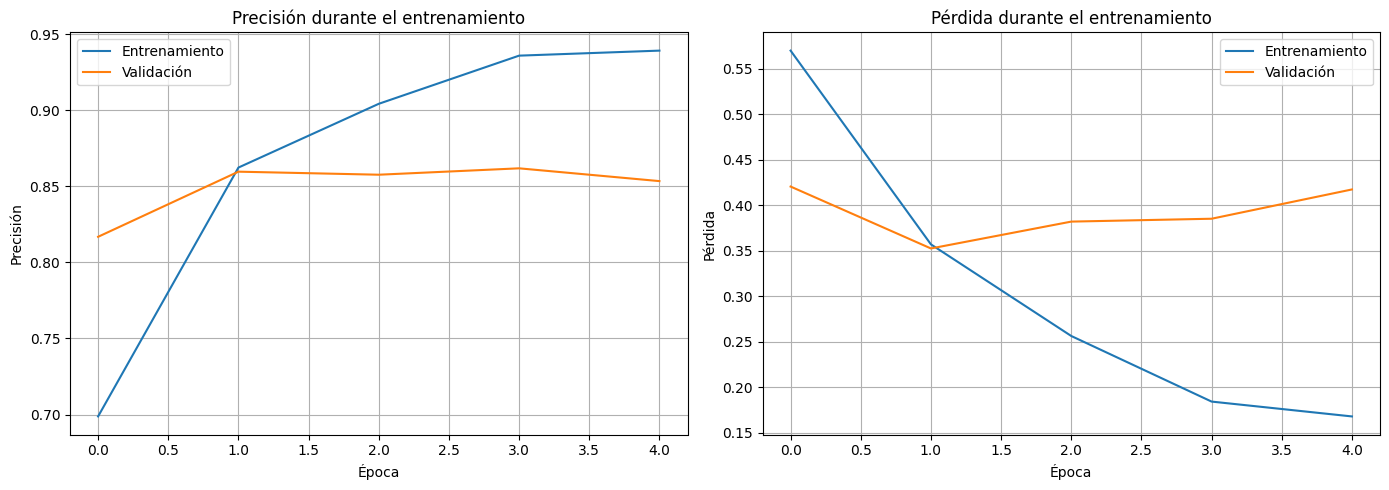

In [9]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Entrenamiento")
plt.plot(history.history["val_accuracy"], label="Validación")
plt.title("Precisión durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Precisión")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")
plt.title("Pérdida durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [10]:
modelo_final = tf.keras.models.load_model(
    "modelo_sentimientos_lstm.keras"
)

resultados = modelo_final.evaluate(
    x_test_pad,
    y_test,
    return_dict=True
)

print("Resultados en el conjunto de prueba:")

for nombre, valor in resultados.items():
    print(f"{nombre}: {valor:.4f}")

782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8480 - loss: 0.4101 - precision: 0.8580 - recall: 0.8341
Resultados en el conjunto de prueba:
accuracy: 0.8480
loss: 0.4101
precision: 0.8580
recall: 0.8341


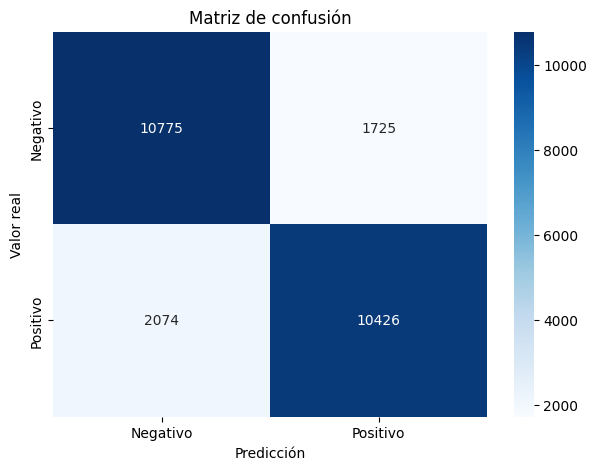

In [11]:
from sklearn.metrics import confusion_matrix, classification_report

probabilidades = modelo_final.predict(x_test_pad, verbose=0).ravel()
predicciones = (probabilidades >= 0.5).astype(int)

matriz = confusion_matrix(y_test, predicciones)

plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negativo", "Positivo"],
    yticklabels=["Negativo", "Positivo"]
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión")
plt.savefig("matriz_confusion_lstm.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
reporte = classification_report(
    y_test,
    predicciones,
    target_names=["Negativo", "Positivo"]
)

print(reporte)

with open("reporte_clasificacion_lstm.txt", "w", encoding="utf-8") as archivo:
    archivo.write(reporte)

              precision    recall  f1-score   support

    Negativo       0.84      0.86      0.85     12500
    Positivo       0.86      0.83      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



In [13]:
# Crear diccionario para convertir números a palabras
word_index = imdb.get_word_index()
reverse_word_index = {value: key for key, value in word_index.items()}

def decodificar_reseña(secuencia):
    palabras = []

    for indice in secuencia:
        if indice >= 3:
            palabra = reverse_word_index.get(indice - 3, "?")
            palabras.append(palabra)

    return " ".join(palabras)

indices = np.random.choice(len(x_test_pad), 10, replace=False)

for numero, indice in enumerate(indices, start=1):
    probabilidad = probabilidades[indice]
    prediccion = "Positivo" if probabilidad >= 0.5 else "Negativo"
    real = "Positivo" if y_test[indice] == 1 else "Negativo"

    print(f"\nPredicción {numero}")
    print("-" * 50)
    print("Reseña:", decodificar_reseña(x_test[indice])[:500])
    print(f"Sentimiento real: {real}")
    print(f"Sentimiento predicho: {prediccion}")
    print(f"Confianza: {max(probabilidad, 1 - probabilidad) * 100:.2f}%")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Predicción 1
--------------------------------------------------
Reseña: while was mildly entertaining and a slightly better way to spend a evening than the pub i did leave pleased that i had got buy one get one free tickets knowing nothing about the film as i went in in fact i didn't even know there was an animated series before i read this site i was ready for anything and as some other viewers noted the trailers showing a well filmed good looking and interesting piece of cinema had pulled me in half way through the film though i was kind of disappointed it did rem
Sentimiento real: Negativo
Sentimiento predicho: Negativo
Confianza: 92.39%

Predicción 2
--------------------------------------------------
Reseña: this must be one of and frank worst films an oddball musical comedy that fails in almost every aspect silly plot has sinatra trying to carry on his fathers reputation as a kissing he's no and doesn't kiss he does play the nerdy 

In [14]:
modelo_final.save("modelo_sentimientos_lstm_final.keras")

print("Modelo guardado correctamente.")

Modelo guardado correctamente.


In [15]:
from google.colab import files

files.download("modelo_sentimientos_lstm_final.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>